# Assignment 1: Data Profiling (EDA) Report

**Domain:** Logistics / Supply Chain  
**Dataset:** DataCo Smart Supply Chain  
**Group Member:** SONG SHIHONG  (A207394)      LI HUA  (A214086)      CHUXINRAN  (A214107)

## 1. Scenario

A regional e-commerce logistics company wants to assess the quality of its order and shipment records before using them to investigate shipping delays. The dataset is suitable because it contains shipping durations, delivery statuses, geographical information, missing values, and potential privacy risks. This assessment aims to identify data quality problems and determine whether the records are sufficiently reliable for future analysis of shipping reliability across regions and shipping modes.

## 2. Data Source

**Dataset:** DataCo Smart Supply Chain for Big Data Analysis

**Kaggle URL:** https://www.kaggle.com/datasets/shashwatwork/dataco-smart-supply-chain-for-big-data-analysis

**Original source:** https://data.mendeley.com/datasets/8gx2fvg2k6/5

**Acquisition method:** The structured CSV file was downloaded from Kaggle and uploaded to GitHub Codespaces for processing using Python and Pandas.

The dataset includes order-item transactions, shipping durations, delivery statuses, geographical attributes, customer information, and financial records.

The assessment focuses on data completeness, uniqueness, validity, consistency, and privacy risks.

## 3. Initial Data Profiling

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

# Locate project root
root = Path.cwd()
if not (root / "data").exists():
    root = root.parent

file_path = root / "data" / "DataCoSupplyChainDataset.csv"

# Load data
df = pd.read_csv(file_path, encoding="latin1")
df.columns = df.columns.str.strip()

df_raw = df.copy()
df_clean = df.copy()

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 180519
Columns: 53


In [50]:
# Data types
display(df.dtypes.to_frame("Data Type"))

# Numeric statistics
display(df.describe().T)

# Column names
print(df.columns.tolist())

,Data Type
Type,str
Days for shipping (real),int64
Days for shipment (scheduled),int64
Benefit per order,float64
Sales per customer,float64
Delivery Status,str
Late_delivery_risk,int64
Category Id,int64
Category Name,str
Customer City,str


,count,mean,std,min,25%,50%,75%,max
Days for shipping (real),180519.0,3.497654,1.623722,0.000000,2.000000,3.000000,5.000000,6.000000
Days for shipment (scheduled),180519.0,2.931847,1.374449,0.000000,2.000000,4.000000,4.000000,4.000000
Benefit per order,180519.0,21.974989,104.433526,-4274.979980,7.000000,31.520000,64.800003,911.799988
Sales per customer,180519.0,183.107609,120.043670,7.490000,104.379997,163.990005,247.399994,1939.989990
Late_delivery_risk,180519.0,0.548291,0.497664,0.000000,0.000000,1.000000,1.000000,1.000000
Category Id,180519.0,31.851451,15.640064,2.000000,18.000000,29.000000,45.000000,76.000000
Customer Id,180519.0,6691.379495,4162.918106,1.000000,3258.500000,6457.000000,9779.000000,20757.000000
Customer Zipcode,180516.0,35921.126914,37542.461122,603.000000,725.000000,19380.000000,78207.000000,99205.000000
Department Id,180519.0,5.443460,1.629246,2.000000,4.000000,5.000000,7.000000,12.000000
Latitude,180519.0,29.719955,9.813646,-33.937553,18.265432,33.144863,39.279617,48.781933


['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product Price', 'Product Status', 'shipping date (DateOrde

In [51]:
# Preview non-sensitive columns
safe_columns = [
    "Order Id",
    "Order Item Id",
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Delivery Status",
    "Shipping Mode",
    "Order Region"
]

display(df[safe_columns].head())

,Order Id,Order Item Id,Days for shipping (real),Days for shipment (scheduled),Delivery Status,Shipping Mode,Order Region
0,77202,180517,3,4,Advance shipping,Standard Class,Southeast Asia
1,75939,179254,5,4,Late delivery,Standard Class,South Asia
2,75938,179253,4,4,Shipping on time,Standard Class,South Asia
3,75937,179252,3,4,Advance shipping,Standard Class,Oceania
4,75936,179251,2,4,Advance shipping,Standard Class,Oceania


## 4. Missing Values

In [52]:
missing_report = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (
        df.isna().mean() * 100
    ).round(2)
})

missing_report = missing_report.sort_values(
    "Missing Count",
    ascending=False
)

display(
    missing_report[
        missing_report["Missing Count"] > 0
    ]
)

,Missing Count,Missing Percentage
Product Description,180519,100.00
Order Zipcode,155679,86.24
Customer Lname,8,0.00
Customer Zipcode,3,0.00


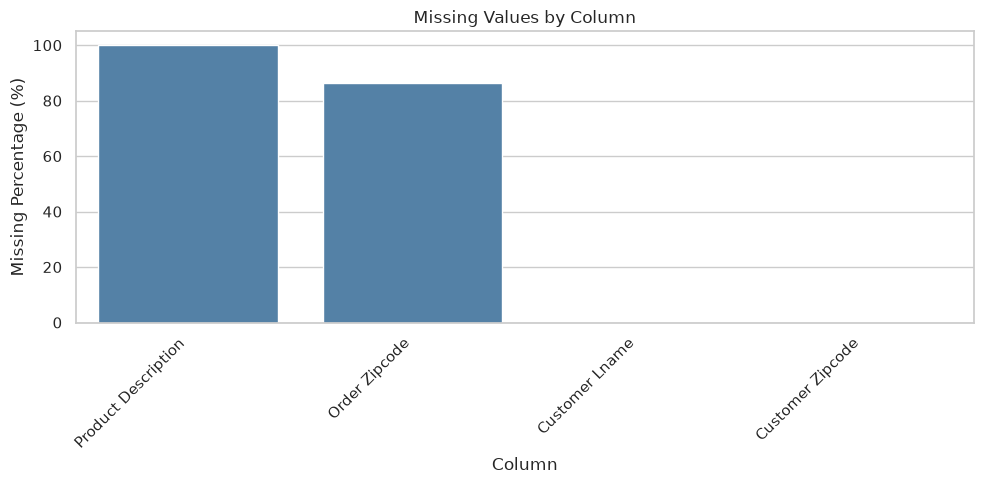

In [53]:
missing_plot = missing_report[
    missing_report["Missing Count"] > 0
]

if len(missing_plot) > 0:
    plt.figure(figsize=(10, 5))

    sns.barplot(
        x=missing_plot.index,
        y=missing_plot["Missing Percentage"],
        color="steelblue"
    )

    plt.title("Missing Values by Column")
    plt.xlabel("Column")
    plt.ylabel("Missing Percentage (%)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values detected.")

In [54]:
# Remove entirely missing columns
all_missing_cols = df_clean.columns[
    df_clean.isna().all()
].tolist()

df_clean = df_clean.drop(
    columns=all_missing_cols
)

print("Removed columns:", all_missing_cols)

# Remaining missing values
display(
    df_clean.isna().sum()[
        df_clean.isna().sum() > 0
    ]
)

Removed columns: ['Product Description']


Customer Lname           8
Customer Zipcode         3
Order Zipcode       155679
dtype: int64

Missing values were identified using `isna()` and summarized using counts and percentages.

The dataset contains 180,519 records and 53 columns. `Product Description` has 180,519 missing values (100%) and was removed because it provides no usable information.

`Order Zipcode` contains 155,679 missing values (86.24%), indicating poor completeness for detailed postal-code analysis. `Customer Lname` and `Customer Zipcode` contain 8 and 3 missing values, respectively.

These remaining fields were initially preserved for profiling and were subsequently excluded during PII minimization because they were not required for the selected logistics assessment. Missing values were not automatically replaced with zero, as inappropriate imputation could introduce misleading information.

The missing-value chart highlights the columns requiring attention and supports the documented decisions about which fields to exclude.

## 5. Outlier Detection

In [55]:
feature = "Benefit per order"

values = pd.to_numeric(
    df_clean[feature],
    errors="coerce"
).dropna()

Q1 = values.quantile(0.25)
Q3 = values.quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outlier_mask = (values < lower) | (values > upper)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower)
print("Upper bound:", upper)
print("Outliers:", outlier_mask.sum())
print("Outlier percentage:",
      round(outlier_mask.mean() * 100, 2))

Q1: 7.0
Q3: 64.80000305
IQR: 57.80000305
Lower bound: -79.70000457500001
Upper bound: 151.50000762500002
Outliers: 18942
Outlier percentage: 10.49


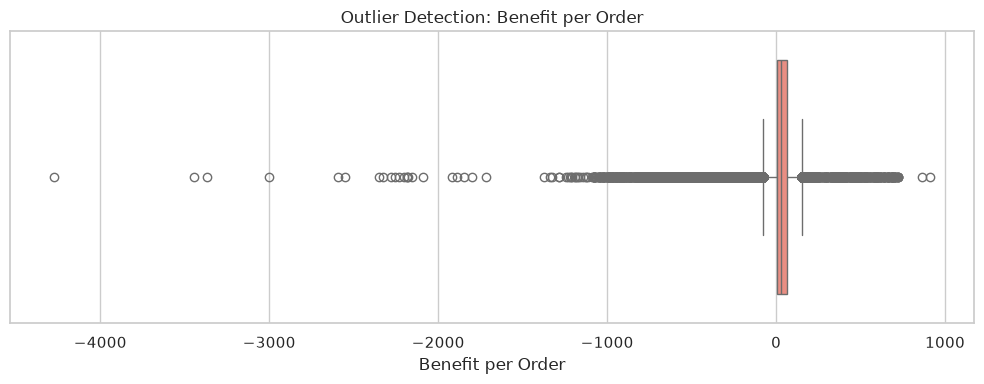

In [56]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=values,
    color="salmon"
)

plt.title("Outlier Detection: Benefit per Order")
plt.xlabel("Benefit per Order")
plt.tight_layout()
plt.show()

In [57]:
df_clean["profit_outlier"] = (
    (df_clean["Benefit per order"] < lower)
    |
    (df_clean["Benefit per order"] > upper)
)

print(df_clean["profit_outlier"].value_counts())

profit_outlier
False    161577
True      18942
Name: count, dtype: int64


The Interquartile Range (IQR) method was applied to the `Benefit per order` feature to detect potential statistical outliers.

The first quartile (Q1) was approximately 7.00, while the third quartile (Q3) was approximately 64.80. The IQR was approximately 57.80, resulting in a lower boundary of -79.70 and an upper boundary of 151.50.

A total of 18,942 records (10.49%) were identified as potential outliers.

These observations were retained and flagged using the Boolean column `profit_outlier`, rather than automatically removed or capped. Unusually high profits or large losses may represent genuine business transactions, and removing them without verification could distort the original financial distribution.

Further business validation would be required to determine whether the flagged values represent errors or legitimate transactions.

## 6. Other Quality Issues

In [58]:
# Exact duplicate rows
duplicates = df_clean.duplicated().sum()

print("Exact duplicates:", duplicates)

# Repeated IDs
print(
    "Repeated Order IDs:",
    df_clean["Order Id"].duplicated().sum()
)

print(
    "Repeated Order Item IDs:",
    df_clean["Order Item Id"].duplicated().sum()
)

# Remove exact duplicates only
df_clean = df_clean.drop_duplicates().copy()

Exact duplicates: 0
Repeated Order IDs: 114767
Repeated Order Item IDs: 0


In [59]:
date_columns = [
    "order date (DateOrders)",
    "shipping date (DateOrders)"
]

for col in date_columns:
    print("\nBefore:", col)
    print("Data type:", df_clean[col].dtype)

    df_clean[col] = pd.to_datetime(
        df_clean[col],
        format="%m/%d/%Y %H:%M",
        errors="coerce"
    )

    print("After:", col)
    print("Data type:", df_clean[col].dtype)
    print("Invalid or missing dates:", df_clean[col].isna().sum())
    print(df_clean[col].head())



Before: order date (DateOrders)
Data type: str
After: order date (DateOrders)
Data type: datetime64[us]
Invalid or missing dates: 0
0   2018-01-31 22:56:00
1   2018-01-13 12:27:00
2   2018-01-13 12:06:00
3   2018-01-13 11:45:00
4   2018-01-13 11:24:00
Name: order date (DateOrders), dtype: datetime64[us]

Before: shipping date (DateOrders)
Data type: str
After: shipping date (DateOrders)
Data type: datetime64[us]
Invalid or missing dates: 0
0   2018-02-03 22:56:00
1   2018-01-18 12:27:00
2   2018-01-17 12:06:00
3   2018-01-16 11:45:00
4   2018-01-15 11:24:00
Name: shipping date (DateOrders), dtype: datetime64[us]


In [60]:
category_columns = [
    "Shipping Mode",
    "Delivery Status",
    "Order Region",
    "Market"
]

for col in category_columns:
    print("\nBefore:", col)
    print(df_clean[col].value_counts(dropna=False).head())

    df_clean[col] = (
        df_clean[col]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .str.title()
    )

    print("After:", col)
    print(df_clean[col].value_counts(dropna=False).head())


Before: Shipping Mode
Shipping Mode
Standard Class    107752
Second Class       35216
First Class        27814
Same Day            9737
Name: count, dtype: int64
After: Shipping Mode
Shipping Mode
Standard Class    107752
Second Class       35216
First Class        27814
Same Day            9737
Name: count, dtype: Int64

Before: Delivery Status
Delivery Status
Late delivery        98977
Advance shipping     41592
Shipping on time     32196
Shipping canceled     7754
Name: count, dtype: int64
After: Delivery Status
Delivery Status
Late Delivery        98977
Advance Shipping     41592
Shipping On Time     32196
Shipping Canceled     7754
Name: count, dtype: Int64

Before: Order Region
Order Region
Central America    28341
Western Europe     27109
South America      14935
Oceania            10148
Northern Europe     9792
Name: count, dtype: int64
After: Order Region
Order Region
Central America    28341
Western Europe     27109
South America      14935
Oceania            10148
Northern 

In [61]:
order_date = df_clean["order date (DateOrders)"]
shipping_date = df_clean["shipping date (DateOrders)"]

df_clean["invalid_date_format"] = (
    order_date.isna()
    |
    shipping_date.isna()
)

df_clean["invalid_date_sequence"] = (
    (shipping_date < order_date)
    &
    ~df_clean["invalid_date_format"]
)

print(
    "Invalid or missing date records:",
    df_clean["invalid_date_format"].sum()
)

print(
    "Invalid date sequences:",
    df_clean["invalid_date_sequence"].sum()
)

print("\nDate data types:")
print(df_clean[
    [
        "order date (DateOrders)",
        "shipping date (DateOrders)"
    ]
].dtypes)

display(
    df_clean.loc[
        df_clean["invalid_date_sequence"],
        [
            "Order Id",
            "order date (DateOrders)",
            "shipping date (DateOrders)"
        ]
    ].head(10)
)


Invalid or missing date records: 0
Invalid date sequences: 0

Date data types:
order date (DateOrders)       datetime64[us]
shipping date (DateOrders)    datetime64[us]
dtype: object


,Order Id,order date (DateOrders),shipping date (DateOrders)


In [62]:
# Shipping date should not precede order date
df_clean["invalid_date_sequence"] = (
    df_clean["shipping date (DateOrders)"]
    <
    df_clean["order date (DateOrders)"]
)

print(
    "Invalid date sequences:",
    df_clean["invalid_date_sequence"].sum()
)

Invalid date sequences: 0


**Duplicate Records:** No exact duplicate rows were identified. A total of 114,767 repeated `Order Id` values were observed, but these were retained because one order can contain multiple order items. No repeated `Order Item Id` values were detected.

**Data Types:** The order and shipping date fields were converted from text to datetime using an explicit date format. Unparseable or missing timestamps were flagged for further investigation.

**Inconsistent Categories:** Shipping modes, delivery statuses, and regions were standardized by removing unnecessary whitespace and applying consistent capitalization. Market labels were cleaned without changing established abbreviations such as `LATAM` and `USCA`.

**Invalid Values:** Shipping durations and order-item quantities were converted to numeric types. Negative or missing shipping durations and non-positive or missing quantities were flagged as invalid or suspicious.

**Date Consistency:** Shipping timestamps were compared with order timestamps after datetime conversion. Records with missing dates were flagged separately from records where the shipping date preceded the order date.

Flagged records were retained to preserve evidence of potential data quality issues rather than being automatically removed.

## 7. Diagnostic Charts

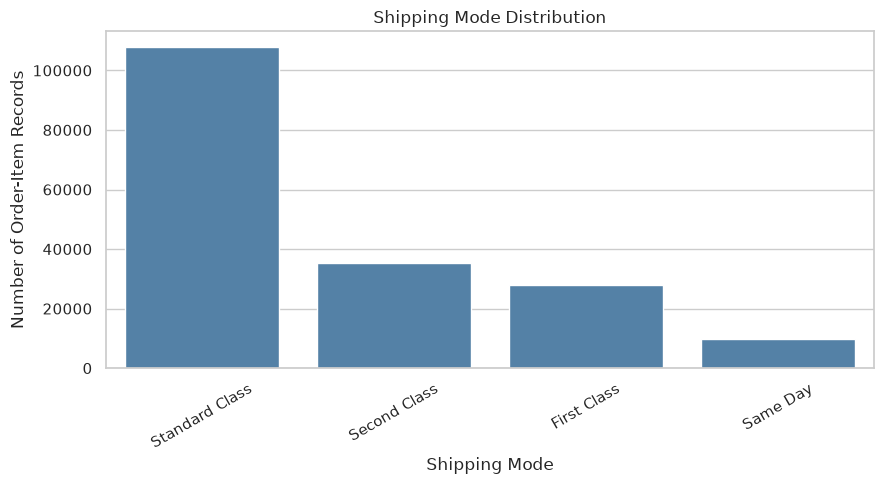

In [63]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_clean,
    x="Shipping Mode",
    order=df_clean["Shipping Mode"].value_counts().index,
    color="steelblue"
)

plt.title("Shipping Mode Distribution")
plt.xlabel("Shipping Mode")
plt.ylabel("Number of Order-Item Records")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 8. PII and Bias Risks

In [64]:
pii_columns = [
    "Customer Fname",
    "Customer Lname",
    "Customer Email",
    "Customer Password",
    "Customer Street",
    "Customer Zipcode",
    "Customer Id",
    "Order Customer Id",
    "Order Zipcode",
    "Latitude",
    "Longitude"
]

existing_pii = [
    col for col in pii_columns
    if col in df_clean.columns
]

print("PII fields identified:")
print(existing_pii)

# Exclude unnecessary PII
df_clean = df_clean.drop(
    columns=existing_pii
)

PII fields identified:
['Customer Fname', 'Customer Lname', 'Customer Email', 'Customer Password', 'Customer Street', 'Customer Zipcode', 'Customer Id', 'Order Customer Id', 'Order Zipcode', 'Latitude', 'Longitude']


In [65]:
region_report = pd.DataFrame({
    "Count": df_clean["Order Region"].value_counts(),
    "Percentage": (
        df_clean["Order Region"]
        .value_counts(normalize=True) * 100
    ).round(2)
})

display(region_report)

,Count,Percentage
Order Region,,
Central America,28341,15.7
Western Europe,27109,15.02
South America,14935,8.27
Oceania,10148,5.62
Northern Europe,9792,5.42
Southeast Asia,9539,5.28
Southern Europe,9431,5.22
Caribbean,8318,4.61
West Of Usa,7993,4.43


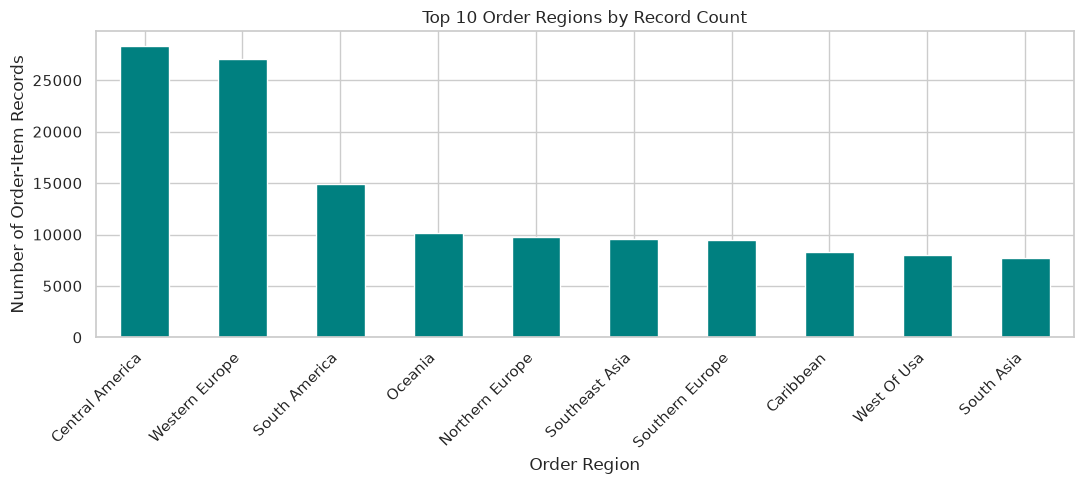

In [66]:
plt.figure(figsize=(11, 5))

df_clean["Order Region"].value_counts().head(10).plot(
    kind="bar",
    color="teal"
)

plt.title("Top 10 Order Regions by Record Count")
plt.xlabel("Order Region")
plt.ylabel("Number of Order-Item Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**PII Risks:** The dataset contains customer-related attributes, including names, addresses, identifiers, and geographic coordinates. These fields are unnecessary for the current logistics data quality assessment and were removed from the cleaned analytical dataset to reduce privacy risks.

**Sampling Bias:** The dataset may contain unequal numbers of records across regions and shipping modes. Regions with larger numbers of records could dominate overall results, while smaller groups may be underrepresented.

**Mitigation:** Group counts and percentages were examined to identify imbalance. Future comparisons should account for group size and avoid generalizing findings beyond the dataset's coverage.

## 9. Final Validation

In [67]:
quality_summary = pd.DataFrame({
    "Metric": [
        "Rows",
        "Columns",
        "Missing Cells",
        "Exact Duplicates"
    ],
    "Before": [
        len(df_raw),
        len(df_raw.columns),
        df_raw.isna().sum().sum(),
        df_raw.duplicated().sum()
    ],
    "After": [
        len(df_clean),
        len(df_clean.columns),
        df_clean.isna().sum().sum(),
        df_clean.duplicated().sum()
    ]
})

display(quality_summary)

,Metric,Before,After
0,Rows,180519,180519
1,Columns,53,44
2,Missing Cells,336209,0
3,Exact Duplicates,0,0


**Interpretation of Data Quality Changes**

The reduction in missing cells mainly resulted from removing the entirely missing `Product Description` column and excluding unnecessary customer-related and location-related fields during PII minimization.

This reduction does not mean that all missing values were corrected or imputed. The comparison reflects changes in the dataset structure as well as improvements in its suitability for the selected analytical purpose.

The original number of records was preserved because no exact duplicate rows were detected. Potential profit outliers and other flagged records were retained for further investigation.

The cleaned dataset should therefore be considered a documented analytical version of the original data rather than a completely error-free dataset.

In [68]:
remaining_issues = pd.Series({
    "Missing Cells": int(df_clean.isna().sum().sum()),
    "Exact Duplicates": int(df_clean.duplicated().sum()),
    "Profit Outliers": int(df_clean["profit_outlier"].sum()),
    "Invalid Shipping Records": int(
        df_clean["invalid_shipping_days"].sum()
    ),
    "Invalid Quantities": int(
        df_clean["invalid_quantity"].sum()
    ),
    "Invalid Date Sequences": int(
        df_clean["invalid_date_sequence"].sum()
    )
})

display(remaining_issues.to_frame("Count"))

KeyError: 'invalid_shipping_days'

In [ ]:
# Save cleaned data locally
output_path = root / "data" / "dataco_cleaned.csv"

df_clean.to_csv(
    output_path,
    index=False
)

print("Saved:", output_path)

Saved: /workspaces/Logistics-Supply-Chain-Data-Profiling/data/dataco_cleaned.csv


## 10. Conclusion

This assessment examined the DataCo Smart Supply Chain dataset for missing values, statistical outliers, duplicate records, incorrect data types, inconsistent categorical formats, invalid values, and privacy risks.

The dataset contains 180,519 records and 53 original columns. The profiling process identified a completely missing product description field, substantial missingness in order postal codes, and 18,942 potential profit outliers (10.49%). No exact duplicate rows were detected, and repeated order identifiers were retained because individual orders may contain multiple items.

The cleaning process removed unnecessary columns, standardized selected categorical values, converted order and shipping timestamps into datetime format, and excluded customer-related information that was not needed for the assessment. Potential outliers and suspicious records were flagged rather than automatically removed.

The dataset is potentially suitable for further analysis of shipping reliability across regions and shipping modes. However, limitations remain, including unequal regional representation, potential financial anomalies, and the lack of independently verified final delivery timestamps.

Additional validation would be necessary before using the dataset for operational decisions. In particular, flagged date inconsistencies and other quality issues should be reviewed against reliable source records.